# Breuer non-Markovianity deep dive (spin-boson, Q = 100)

Answers Kurt's requests R3, R4, R5 and R13 (28 May and 6 Sep 2026):

* **R3** – all pair integrals $\int_{\sigma>0}\sigma\,dt$ at Q = 100, not just the maximum;
* **R4** – the same using only the first half of the run time;
* **R13** – running integral of $\max(0, dD/dt)$ vs time for all trajectory pairs at Q = 100, on one plot;
* **R5** – for the pair that gives the Breuer maximum at each Q, the integrated trace distance to the best-fit (SID) trajectories.

The Breuer measure is computed exactly as in `NonMarkovianity.ipynb` (sum of positive increments of the
trace distance between the sampled trajectories, maximised over the 91 pairs of the 14 initial states),
so the maxima reproduce `NonMark.pkl`. Pure Python: reads `DATA/ALL_GAMMAS_B4_D10.h5`, the fitted models
and the trace-distance rescore files.

Outputs go to `BREUER_Q100/`.

In [1]:
import itertools, os, glob, pickle
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm

os.makedirs("BREUER_Q100", exist_ok=True)

evol_data  = "DATA/ALL_GAMMAS_B4_D10.h5"
γ_list     = ["0.079477","0.25133","0.79477","2.5133","7.9477","25.133","79.477","251.33"]
Q          = [316, 100, 31.6, 10, 3.16, 1, 0.316, 0.1]
all_states = [f"B{i}" for i in range(1,5)] + [f"D{i}" for i in range(1,11)]
pairs      = list(itertools.combinations(all_states, 2))      # 91 pairs
γ_Q100     = "0.25133"

color_blind_palette = ["#009E73", "#E69F00", "#CC79A7", "#0072B2", "#D55E00"]
plt.rcParams.update({"font.size": 13, "axes.labelsize": 14, "legend.fontsize": 11})

In [2]:
def read_timeevolution(state, γ_i, file=evol_data):
    """t, p0 (= ground population ρ₀₀) and coherence ρ₀₁, as LiPoSID.read_timeevolution."""
    with h5py.File(file, "r") as f:
        d = f[state][γ_i]
        t  = np.ravel(d["t"][...])
        p0 = np.ravel(d["p0"][...])
        s  = np.ravel(d["s_re"][...]) + 1j*np.ravel(d["s_im"][...])
    return t, p0, s

def trace_distance(p0a, sa, p0b, sb):
    """Closed form for qubits: eigenvalues of ρa-ρb are ±sqrt(Δp² + |Δs|²)."""
    n = min(len(p0a), len(p0b))                      # zip() truncation, as in the Julia code
    return np.sqrt((p0a[:n]-p0b[:n])**2 + np.abs(sa[:n]-sb[:n])**2)

def breuer_integral(D, mask=None):
    """Discrete Breuer integral: sum of positive increments of D (optionally only increments in mask)."""
    dD = np.diff(D)
    if mask is not None:
        dD = dD[mask[1:]]
    return dD[dD > 0].sum()

traj = {γ_i: {s: read_timeevolution(s, γ_i) for s in all_states} for γ_i in γ_list}

## 1. All pair integrals for every Q, full and half run time (R3, R4)

In [3]:
rows = []
for γ_i, Q_i in zip(γ_list, Q):
    for a, b in pairs:
        ta, pa, sa = traj[γ_i][a]
        _,  pb, sb = traj[γ_i][b]
        D = trace_distance(pa, sa, pb, sb)
        t = ta[:len(D)]
        t_half = t[0] + (t[-1] - t[0]) / 2
        rows.append(dict(gamma=γ_i, Q=Q_i, state_a=a, state_b=b,
                         N_full=breuer_integral(D),
                         N_half=breuer_integral(D, t <= t_half),
                         t_start=t[0], t_end=t[-1]))
pairs_df = pd.DataFrame(rows)
pairs_df.to_csv("BREUER_Q100/breuer_all_pairs_all_Q.csv", index=False)

# Check: the maxima must reproduce NonMark.pkl from NonMarkovianity.ipynb
with open("NonMark.pkl", "rb") as fh:
    NonMark = np.asarray(pickle.load(fh), dtype=float)
N_max = pairs_df.groupby("gamma", sort=False)["N_full"].max().values
print("max |N(python) - N(julia)| =", np.abs(N_max - NonMark).max())

max |N(python) - N(julia)| = 1.700029006457271e-16


In [4]:
def pair_summary(df):
    out = []
    for (γ_i, Q_i), g in df.groupby(["gamma", "Q"], sort=False):
        ifull, ihalf = g["N_full"].idxmax(), g["N_half"].idxmax()
        out.append(dict(Q=Q_i, gamma=γ_i,
                        N_max_full=g.loc[ifull, "N_full"],
                        max_pair_full=f'{g.loc[ifull,"state_a"]}-{g.loc[ifull,"state_b"]}',
                        N_median_full=g["N_full"].median(),
                        pairs_zero_full=int((g["N_full"] == 0).sum()),
                        N_max_half=g.loc[ihalf, "N_half"],
                        max_pair_half=f'{g.loc[ihalf,"state_a"]}-{g.loc[ihalf,"state_b"]}' if g["N_half"].max() > 0 else "-",
                        pairs_zero_half=int((g["N_half"] == 0).sum()),
                        run_time=g["t_end"].max() - g["t_start"].min()))
    return pd.DataFrame(out)

summary = pair_summary(pairs_df)
summary.to_csv("BREUER_Q100/breuer_summary_full_vs_half.csv", index=False)
pd.set_option("display.width", 200)
summary

,Q,gamma,N_max_full,max_pair_full,N_median_full,pairs_zero_full,N_max_half,max_pair_half,pairs_zero_half,run_time
0,316.000,0.079477,0.000154,D7-D8,0.000000,53,0.000000,-,91,25.100000
1,100.000,0.25133,0.012929,B3-D8,0.003135,0,0.000000,-,91,23.813333
2,31.600,0.79477,0.000059,D5-D6,0.000001,10,0.000042,D5-D6,74,8.755000
3,10.000,2.5133,0.000710,D5-D6,0.000068,5,0.000325,D5-D6,62,2.733750
4,3.160,7.9477,0.034632,B4-D6,0.004641,6,0.004042,D5-D6,56,0.704000
5,1.000,25.133,0.041877,B2-B3,0.000000,74,0.000005,B3-D4,87,0.162950
6,0.316,79.477,0.003018,D3-D5,0.000000,50,0.000047,D1-D8,86,0.175300
7,0.100,251.33,0.000640,B1-B3,0.000000,78,0.000085,D2-D7,86,0.064450


In [5]:
q100 = pairs_df[pairs_df.gamma == γ_Q100].sort_values("N_full", ascending=False).reset_index(drop=True)
print(f"Q = 100: {len(q100)} pairs, {int((q100.N_full > 0).sum())} with N > 0 over the full run, "
      f"{int((q100.N_half > 0).sum())} with N > 0 over the first half")
q100.head(10)

Q = 100: 91 pairs, 91 with N > 0 over the full run, 0 with N > 0 over the first half


,gamma,Q,state_a,state_b,N_full,N_half,t_start,t_end
0,0.25133,100.0,B3,D8,0.012929,0.0,0.053333,23.866667
1,0.25133,100.0,D7,D8,0.012540,0.0,0.053333,23.866667
2,0.25133,100.0,D3,D8,0.009974,0.0,0.053333,23.866667
3,0.25133,100.0,D1,D8,0.009972,0.0,0.053333,23.866667
4,0.25133,100.0,D4,D8,0.009233,0.0,0.053333,23.866667
5,0.25133,100.0,D2,D8,0.009227,0.0,0.053333,23.866667
6,0.25133,100.0,D8,D10,0.008411,0.0,0.053333,23.866667
7,0.25133,100.0,D8,D9,0.008409,0.0,0.053333,23.866667
8,0.25133,100.0,B1,B3,0.006595,0.0,0.053333,23.866667
9,0.25133,100.0,B2,B3,0.006594,0.0,0.053333,23.866667


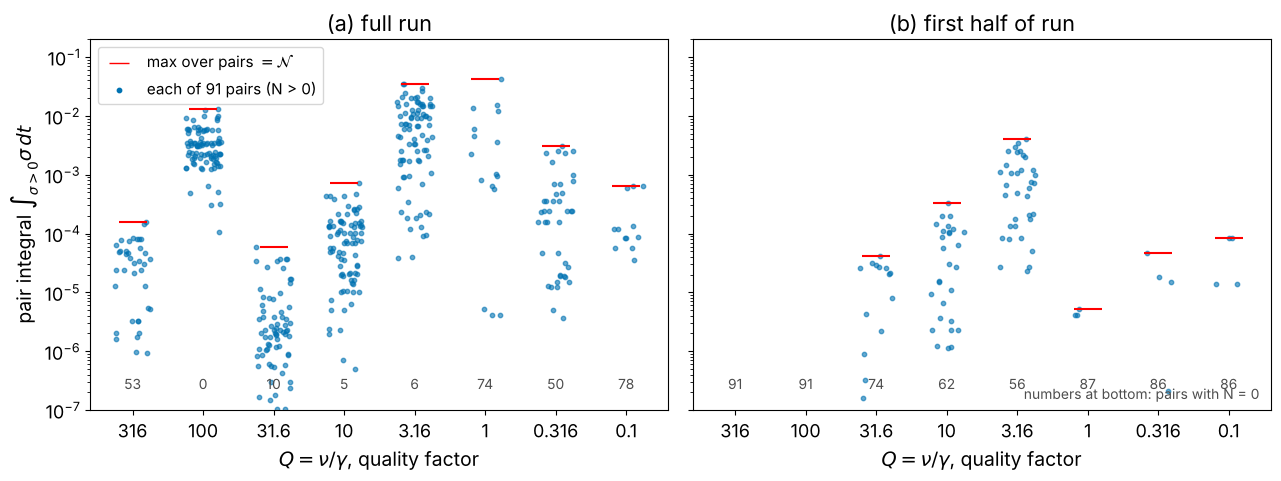

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
x = np.arange(1, len(Q) + 1)
rng = np.random.default_rng(0)
for ax, col, title in [(axs[0], "N_full", "(a) full run"), (axs[1], "N_half", "(b) first half of run")]:
    for i, γ_i in enumerate(γ_list):
        v = pairs_df.loc[pairs_df.gamma == γ_i, col].values
        pos = v[v > 0]
        ax.scatter(x[i] + rng.uniform(-0.25, 0.25, len(pos)), pos, s=10, alpha=0.6,
                   color=color_blind_palette[3])
        if len(pos):
            ax.scatter(x[i], pos.max(), marker="_", s=400, color="red", zorder=3)
        nzero = int((v == 0).sum())
        ax.text(x[i], 2e-7, f"{nzero}", ha="center", va="bottom", fontsize=10, color="0.3")
    ax.set_yscale("log"); ax.set_ylim(1e-7, 0.2); ax.set_xlim(0.4, len(Q) + 0.6)
    ax.set_xticks(x, Q); ax.set_xlabel(r"$Q=\nu/\gamma$, quality factor")
    ax.set_title(title)
axs[0].set_ylabel(r"pair integral $\int_{\sigma>0}\sigma\,dt$")
axs[0].plot([], [], "_", color="red", ms=15, label=r"max over pairs $=\mathcal{N}$")
axs[0].scatter([], [], s=10, color=color_blind_palette[3], label="each of 91 pairs (N > 0)")
axs[0].legend(loc="upper left")
axs[1].text(0.98, 0.03, "numbers at bottom: pairs with N = 0", transform=axs[1].transAxes,
            ha="right", fontsize=10, color="0.3")
plt.tight_layout()
fig.savefig("BREUER_Q100/BREUER_all_pairs_full_vs_half.pdf")
plt.show()

## 2. Running integral of max(0, dD/dt) at Q = 100, all pairs (R13)

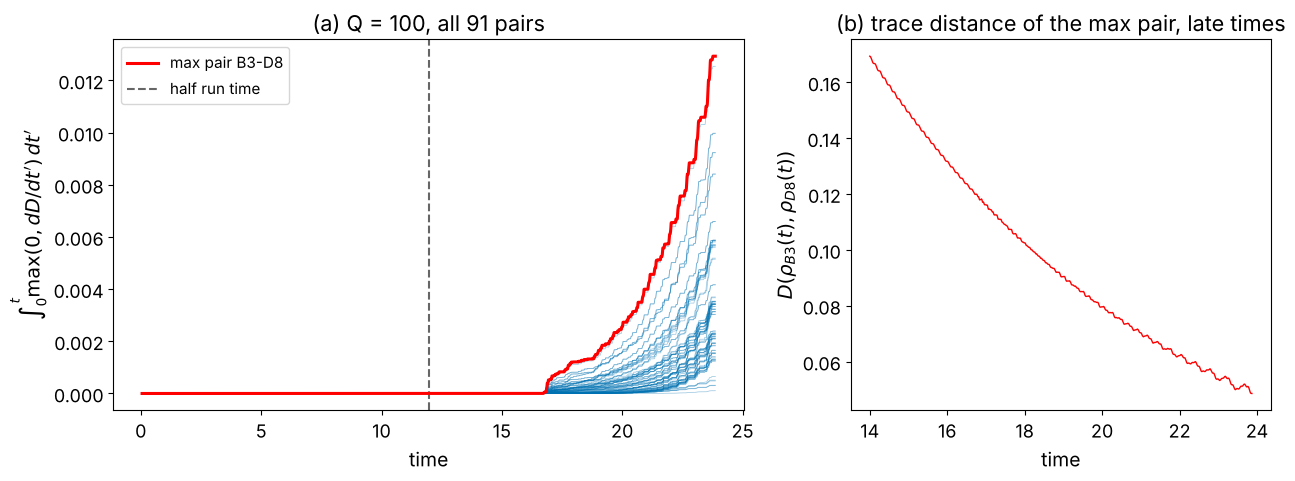

first positive increment, over all pairs with N > 0: earliest t = 16.627, median t = 16.807; run is t = 0.053 to 23.867


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[3, 2]))
max_a, max_b = q100.loc[0, "state_a"], q100.loc[0, "state_b"]
t_q, _, _ = traj[γ_Q100]["B1"]
onsets = []
for a, b in pairs:
    _, pa, sa = traj[γ_Q100][a]; _, pb, sb = traj[γ_Q100][b]
    D = trace_distance(pa, sa, pb, sb)
    run = np.concatenate([[0.0], np.cumsum(np.clip(np.diff(D), 0, None))])
    first = np.argmax(np.diff(D) > 0) + 1 if (np.diff(D) > 0).any() else None
    if first is not None:
        onsets.append(t_q[first])
    is_max = (a, b) == (max_a, max_b)
    axs[0].plot(t_q[:len(run)], run, lw=2.2 if is_max else 0.6,
                color="red" if is_max else color_blind_palette[3], alpha=1 if is_max else 0.35,
                zorder=3 if is_max else 1, label=f"max pair {a}-{b}" if is_max else None)
    if is_max:
        D_max = D
t_half = t_q[0] + (t_q[-1] - t_q[0]) / 2
axs[0].axvline(t_half, ls="--", color="0.4", label="half run time")
axs[0].set_xlabel("time"); axs[0].set_ylabel(r"$\int_0^t \max(0, dD/dt')\,dt'$")
axs[0].set_title(f"(a) Q = 100, all {len(pairs)} pairs"); axs[0].legend(loc="upper left")

late = t_q > 14
axs[1].plot(t_q[late], D_max[late], color="red", lw=1)
axs[1].set_xlabel("time"); axs[1].set_ylabel(r"$D(\rho_{%s}(t),\rho_{%s}(t))$" % (max_a, max_b))
axs[1].set_title("(b) trace distance of the max pair, late times")
plt.tight_layout()
fig.savefig("BREUER_Q100/BREUER_Q100_running_integral_all_pairs.pdf")
plt.show()
onsets = np.array(onsets)
print(f"first positive increment, over all pairs with N > 0: earliest t = {onsets.min():.3f}, "
      f"median t = {np.median(onsets):.3f}; run is t = {t_q[0]:.3f} to {t_q[-1]:.3f}")

## 3. Is the Q = 100 value robust to the sampling?

Every positive increment at Q = 100 occurs after t ≈ 16.7, i.e. in the last 30 % of the run, where the
trace distances are already small (≈ 0.1) and step-to-step jitter of order 1e-4 is comparable to the decay
per step. If this were a physical revival of distinguishability it would survive coarser sampling and a
short moving average. Below: the Breuer maximum recomputed with every k-th sample, and after a moving
average of width 0.5 (two periods of the qubit oscillation 2π/ν ≈ 0.25) — the latter only for Q ≥ 10,
where the run is many periods long.

In [8]:
def breuer_max(γ_i, k=1, smooth=None):
    best = 0.0
    for a, b in pairs:
        ta, pa, sa = traj[γ_i][a]; _, pb, sb = traj[γ_i][b]
        D = trace_distance(pa, sa, pb, sb)
        if smooth is not None:
            w = max(1, int(round(smooth / (ta[1] - ta[0]))))
            D = np.convolve(D, np.ones(w) / w, mode="valid")
        best = max(best, breuer_integral(D[::k]))
    return best

robust = pd.DataFrame(dict(
    Q=Q,
    N_every_sample=[breuer_max(g) for g in γ_list],
    N_every_2nd=[breuer_max(g, 2) for g in γ_list],
    N_every_4th=[breuer_max(g, 4) for g in γ_list],
    N_every_8th=[breuer_max(g, 8) for g in γ_list],
    N_moving_avg_0p5=[breuer_max(g, smooth=0.5) if q >= 10 else np.nan for g, q in zip(γ_list, Q)],
))
robust.to_csv("BREUER_Q100/breuer_sampling_robustness.csv", index=False)
robust

,Q,N_every_sample,N_every_2nd,N_every_4th,N_every_8th,N_moving_avg_0p5
0,316.000,0.000154,0.000013,0.000000,0.000000,0.0
1,100.000,0.012929,0.012136,0.009985,0.006976,0.0
2,31.600,0.000059,0.000020,0.000002,0.000000,0.0
3,10.000,0.000710,0.000687,0.000632,0.000495,0.0
4,3.160,0.034632,0.034629,0.034603,0.034361,NaN
5,1.000,0.041877,0.041830,0.041736,0.041736,NaN
6,0.316,0.003018,0.003018,0.003018,0.003018,NaN
7,0.100,0.000640,0.000639,0.000639,0.000639,NaN


## 4. Max pair vs the best-fit SID trajectories (R5)

For the pair giving the Breuer maximum at each Q we integrate the trace distance between the exact
trajectory and the SID trajectory (same initial state) for both states of the pair:
$\int T(\rho_{\rm exact}(t), \rho_{\rm SID}(t))\,dt$, and the same divided by the run time (the runs have
very different lengths, from 0.06 to 25). Trace distances come from the rescore files written by
`03B_rescore_tracedist_allstates.ipynb`. As in the paper figures, the Lindblad ansatz is used for
Q ≥ 10 and the Kossakowski ansatz for Q ≤ 3.16; both are tabulated.

In [9]:
def latest_file(pattern):
    return sorted(glob.glob(pattern))[-1]

rescore = {"Lindblad": latest_file("E_LINDBLAD_TRACEDIST_ALLSTATES_*.h5"),
           "Kossakowski": latest_file("E_KOSSAK_TRACEDIST_ALLSTATES_*.h5")}
print(rescore)

def integrated_td(file, γ_i, state):
    with h5py.File(file, "r") as f:
        td = np.ravel(f[γ_i][state]["TraceDist"][...]); t = np.ravel(f[γ_i][state]["time"][...])
    return np.trapezoid(td, t), t[-1] - t[0]

r5 = []
for γ_i, Q_i in zip(γ_list, Q):
    g = pairs_df[pairs_df.gamma == γ_i]
    best = g.loc[g.N_full.idxmax()]
    for ansatz, file in rescore.items():
        all_int = [integrated_td(file, γ_i, s) for s in all_states]
        for s in (best.state_a, best.state_b):
            I, T = integrated_td(file, γ_i, s)
            r5.append(dict(Q=Q_i, gamma=γ_i, ansatz=ansatz, max_pair=f"{best.state_a}-{best.state_b}",
                           N=best.N_full, state=s, int_TD=I, run_time=T, mean_TD=I / T,
                           mean_TD_all_states_median=np.median([i / t for i, t in all_int])))
r5 = pd.DataFrame(r5)
r5.to_csv("BREUER_Q100/maxpair_integrated_tracedist_to_fit.csv", index=False)
paper_ansatz = lambda q: "Lindblad" if q >= 10 else "Kossakowski"
r5[r5.apply(lambda r: r.ansatz == paper_ansatz(r.Q), axis=1)].reset_index(drop=True)

{'Lindblad': 'E_LINDBLAD_TRACEDIST_ALLSTATES_2026-07-12.h5', 'Kossakowski': 'E_KOSSAK_TRACEDIST_ALLSTATES_2026-07-12.h5'}


,Q,gamma,ansatz,max_pair,N,state,int_TD,run_time,mean_TD,mean_TD_all_states_median
0,316.000,0.079477,Lindblad,D7-D8,0.000154,D7,0.771434,25.100000,0.030734,0.024971
1,316.000,0.079477,Lindblad,D7-D8,0.000154,D8,0.771941,25.100000,0.030755,0.024971
2,100.000,0.25133,Lindblad,B3-D8,0.012929,B3,0.023949,23.813333,0.001006,0.000855
3,100.000,0.25133,Lindblad,B3-D8,0.012929,D8,0.027220,23.813333,0.001143,0.000855
4,31.600,0.79477,Lindblad,D5-D6,0.000059,D5,0.019299,8.755000,0.002204,0.002106
5,31.600,0.79477,Lindblad,D5-D6,0.000059,D6,0.019298,8.755000,0.002204,0.002106
6,10.000,2.5133,Lindblad,D5-D6,0.000710,D5,0.016569,2.733750,0.006061,0.006111
7,10.000,2.5133,Lindblad,D5-D6,0.000710,D6,0.016841,2.733750,0.006160,0.006111
8,3.160,7.9477,Kossakowski,B4-D6,0.034632,B4,0.014592,0.704000,0.020727,0.018251
9,3.160,7.9477,Kossakowski,B4-D6,0.034632,D6,0.019143,0.704000,0.027192,0.018251


Cross-check at Q = 100: evolve the fitted Lindblad model in Python (exact propagator on the data grid) and
compare with the stored rescore trace distance. Then plot the pair's trace distance for the exact data and
for the SID model: a GKSL model is CP-divisible, so its $D(t)$ can never increase.

In [10]:
def lindblad_superop(H, Js):
    """Column-stacking Liouvillian of dρ/dt = -i[H,ρ] + Σ (JρJ† - ½{J†J,ρ})."""
    I = np.eye(2)
    L = -1j * (np.kron(I, H) - np.kron(H.T, I))
    for J in Js:
        JdJ = J.conj().T @ J
        L += np.kron(J.conj(), J) - 0.5 * (np.kron(I, JdJ) + np.kron(JdJ.T, I))
    return L

def evolve(L, ρ0, t):
    P = expm(L * (t[1] - t[0]))                      # uniform grid
    v = ρ0.reshape(-1, order="F"); out = []
    for _ in t:
        out.append(v.reshape(2, 2, order="F")); v = P @ v
    return np.array(out)

def rho(p0, s):
    return np.array([[p0, s], [np.conj(s), 1 - p0]])

with h5py.File(latest_file("E_LINDBLAD4_CONSTR_TSSOS_*.h5"), "r") as f:
    g = f[γ_Q100]
    H  = g["H"][...].T                               # Julia column-major → transpose
    Js = [g[f"J{i}"][...].T for i in range(1, 5)]
L = lindblad_superop(H, Js)

fit_D = {}
for s in (max_a, max_b):
    t, p0, sc = traj[γ_Q100][s]
    ρ_fit = evolve(L, rho(p0[0], sc[0]), t)
    fit_D[s] = ρ_fit
    td_py = trace_distance(p0, sc, ρ_fit[:, 0, 0].real, ρ_fit[:, 0, 1])
    with h5py.File(rescore["Lindblad"], "r") as f:
        td_jl = f[γ_Q100][s]["TraceDist"][...]
    print(f"{s}: max |TD(python) - TD(julia rescore)| = {np.abs(td_py - td_jl).max():.2e}")

D_fit = trace_distance(fit_D[max_a][:, 0, 0].real, fit_D[max_a][:, 0, 1],
                       fit_D[max_b][:, 0, 0].real, fit_D[max_b][:, 0, 1])
print("Breuer integral of the fitted model pair:", breuer_integral(D_fit))

B3: max |TD(python) - TD(julia rescore)| = 5.18e-06
D8: max |TD(python) - TD(julia rescore)| = 5.22e-06
Breuer integral of the fitted model pair: 0.0


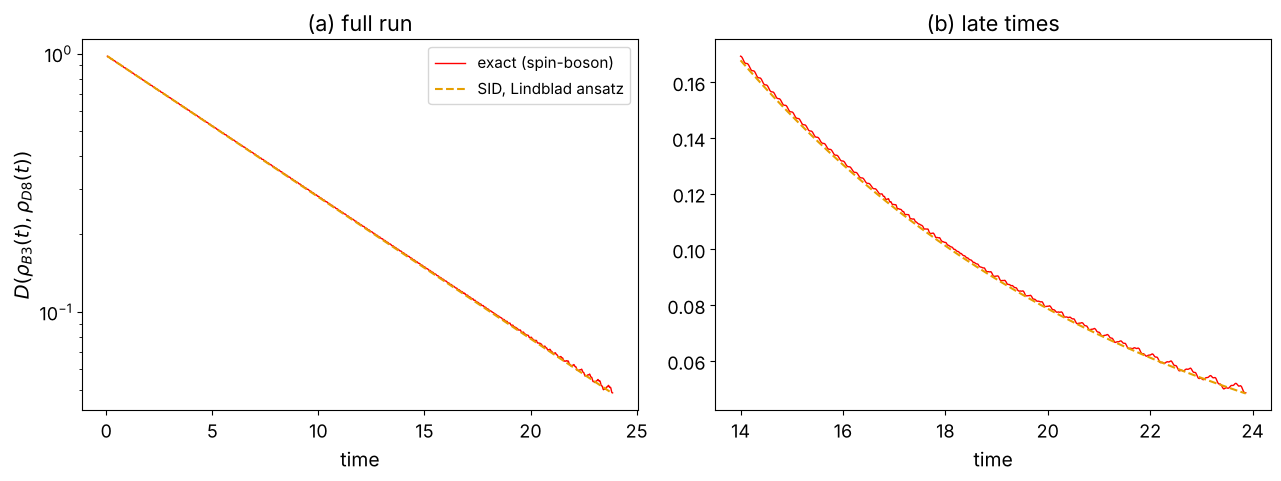

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, sel, title in [(axs[0], slice(None), "(a) full run"), (axs[1], t_q > 14, "(b) late times")]:
    ax.plot(t_q[sel], D_max[sel], color="red", lw=1, label="exact (spin-boson)")
    ax.plot(t_q[sel], D_fit[sel], color=color_blind_palette[1], lw=1.5, ls="--", label="SID, Lindblad ansatz")
    ax.set_xlabel("time"); ax.set_title(title)
axs[0].set_yscale("log")
axs[0].set_ylabel(r"$D(\rho_{%s}(t),\rho_{%s}(t))$" % (max_a, max_b)); axs[0].legend()
plt.tight_layout()
fig.savefig("BREUER_Q100/BREUER_Q100_maxpair_exact_vs_SID.pdf")
plt.show()

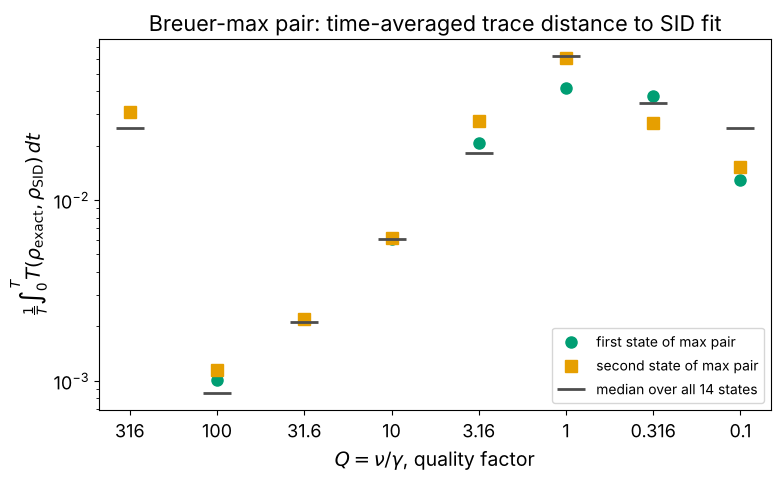

In [12]:
sel = r5[r5.apply(lambda r: r.ansatz == paper_ansatz(r.Q), axis=1)]
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(1, len(Q) + 1)
for k, (lab, mk) in enumerate([("first state of max pair", "o"), ("second state of max pair", "s")]):
    v = [sel[sel.gamma == γ_i]["mean_TD"].values[k] for γ_i in γ_list]
    ax.plot(x, v, mk, color=color_blind_palette[k], ms=8, label=lab)
med = sel.groupby("gamma", sort=False)["mean_TD_all_states_median"].first().reindex(γ_list).values
ax.plot(x, med, "_", color="0.3", ms=20, mew=2, label="median over all 14 states")
ax.set_yscale("log"); ax.set_xticks(x, Q)
ax.set_xlabel(r"$Q=\nu/\gamma$, quality factor")
ax.set_ylabel(r"$\frac{1}{T}\int_0^T T(\rho_{\rm exact},\rho_{\rm SID})\,dt$")
ax.set_title("Breuer-max pair: time-averaged trace distance to SID fit")
ax.legend(loc="lower right", fontsize=10)
plt.tight_layout()
fig.savefig("BREUER_Q100/BREUER_maxpair_mean_tracedist_to_SID.pdf")
plt.show()

## Findings (numbers from the cells above)

* **The Q = 100 spike comes entirely from the end of the run.** All 91 pairs have $N>0$ at Q = 100, but
  for every pair the first positive increment of $D(t)$ is at t ≥ 16.6 (run: 0.05 to 23.9). Before that,
  every trace distance decreases monotonically. Over the first half of the run, $N = 0$ for all 91 pairs (R4).
* **It is not robust to the sampling.** Taking every 8th sample cuts the Q = 100 value from 0.0129 to 0.0070,
  and a moving average over two qubit periods removes it. The same averaging also removes the
  (much smaller) values at Q = 316, 31.6 and 10. By contrast, the strong-coupling values (Q ≤ 3.16) do not
  change with decimation, so those are genuine information backflow at early times.
* **What drives it:** $D(t)$ decays as $e^{-\gamma t/2}$ with a 0.18 % ripple at ≈ 2ν (counter-rotating
  terms); this ripple alone never makes $dD/dt>0$. After t ≈ 16 an additional small oscillation
  (absolute size ~1e-4, growing towards the end, ω ≈ 16 to 19) appears in the exact data while $D$ itself is
  ≈ 0.1, and that tips the increments positive. Whether this is a bath recurrence from the finite bath
  discretisation or integrator error in the spin-boson simulation is a question for whoever generated the
  data (Kurt).
* **R5:** the Breuer-max pair is fitted no worse than a typical initial state. At Q = 100 its time-averaged
  trace distance to the Lindblad SID trajectory is 1.0e-3 and 1.1e-3, against a median of 0.86e-3 over all
  14 states; the SID pair's own $D(t)$ is strictly decreasing (Breuer integral 0), as it must be for a GKSL
  model.
* Because of the above, the non-Markovianity curve used in the paper figures (twin axis in the violin and
  max-trace-distance plots) should probably be recomputed on a run window or sampling that excludes the
  late-time artefact, or the Q = 100 point should be flagged.